# Ciclo de vida del modelo: chatbot de preguntas frecuentes UPQ

**Objetivo:** comparar cuatro clasificadores supervisados sobre el mismo corpus, con el
mismo procedimiento de evaluación (validación cruzada estratificada, F1 macro y matrices
de confusión), y justificar cuál se usa en el chatbot.

**Restricción de la tarea:** solo aprendizaje supervisado clásico con TF-IDF y
scikit-learn, todo local.

In [34]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

RAIZ = Path.cwd().parent
assert (RAIZ / "src").exists(), f"No encuentro src/ en {RAIZ}; ¿abriste el notebook desde notebooks/?"
sys.path.insert(0, str(RAIZ))

from src.preprocesamiento import limpiar_texto

print("Proyecto:", RAIZ)

Proyecto: /home/baz/Downloads/repos/chatbot-upq


32 ejemplos, 3 intenciones
intencion
becas                 20
admision               6
calendario_escolar     6
Name: count, dtype: int64


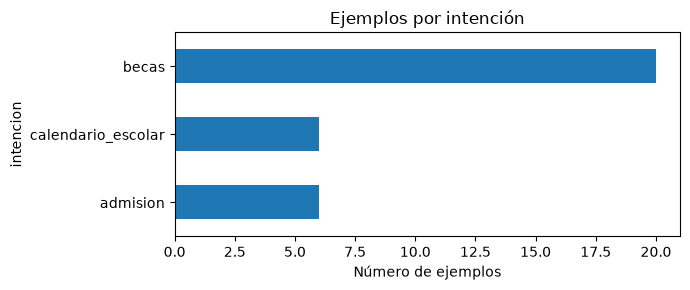

In [35]:
corpus = pd.read_csv(RAIZ / "data" / "corpus_upq.csv")
conteo = corpus["intencion"].value_counts()
print(f"{len(corpus)} ejemplos, {corpus['intencion'].nunique()} intenciones")
print(conteo)

conteo.sort_values().plot.barh(figsize=(7, 3), title="Ejemplos por intención")
plt.xlabel("Número de ejemplos")
plt.tight_layout()
plt.show()

In [36]:
corpus["texto_limpio"] = corpus["texto"].map(limpiar_texto)
corpus[["texto", "texto_limpio"]].sample(5, random_state=42)

,texto,texto_limpio
29,¿La universidad da becas de manutención?,la universidad da becas de manutencion
15,calendario escolar 2026,calendario escolar 2026
24,Soy alumno de primer cuatrimestre y quiero sab...,soy alumno de primer cuatrimestre y quiero sab...
17,que dia regresamos de vacaciones,que dia regresamos de vacaciones
8,¿Qué apoyos económicos ofrece la universidad?,que apoyos economicos ofrece la universidad


In [37]:
X = corpus["texto_limpio"]
y = corpus["intencion"]

n_splits = min(5, y.value_counts().min())
folds = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
print(f"Validación cruzada estratificada con {n_splits} folds")


def tfidf():
    return TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True)


modelos = {
    "LogisticRegression": LogisticRegression(max_iter=1000, random_state=42),
    "LinearSVC": LinearSVC(random_state=42),
    "MultinomialNB": MultinomialNB(),
    "KNN (coseno, k=3)": KNeighborsClassifier(n_neighbors=3, metric="cosine"),
}
pipelines = {n: Pipeline([("tfidf", tfidf()), ("clf", clf)]) for n, clf in modelos.items()}

filas = []
for nombre, pipe in pipelines.items():
    r = cross_validate(pipe, X, y, cv=folds, scoring=["f1_macro", "accuracy"])
    filas.append({
        "modelo": nombre,
        "f1_macro": r["test_f1_macro"].mean(),
        "f1_desv": r["test_f1_macro"].std(),
        "accuracy": r["test_accuracy"].mean(),
        "acc_desv": r["test_accuracy"].std(),
    })

resultados = pd.DataFrame(filas).sort_values("f1_macro", ascending=False).reset_index(drop=True)
resultados.round(3)

Validación cruzada estratificada con 5 folds


,modelo,f1_macro,f1_desv,accuracy,acc_desv
0,LinearSVC,0.586,0.052,0.752,0.068
1,"KNN (coseno, k=3)",0.504,0.150,0.619,0.099
2,LogisticRegression,0.257,0.012,0.629,0.047
3,MultinomialNB,0.257,0.012,0.629,0.047


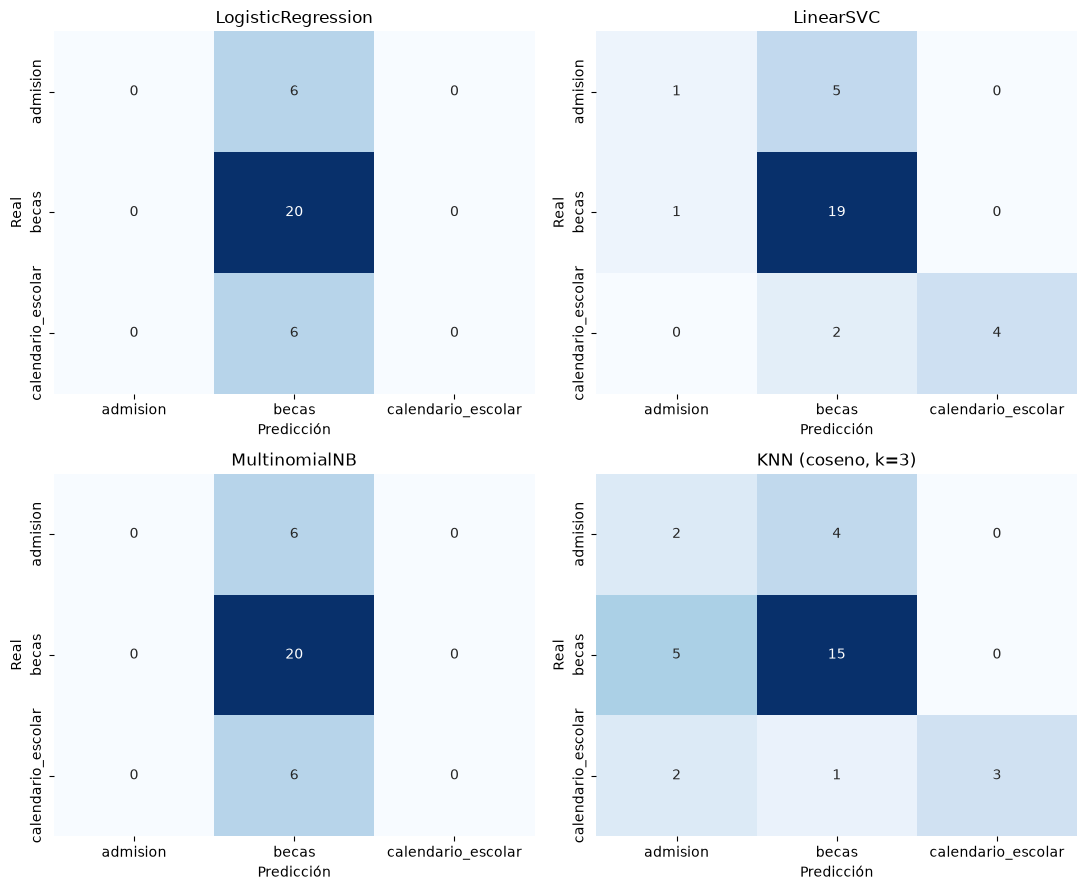

In [38]:
orden = sorted(y.unique())
predicciones = {}

fig, ejes = plt.subplots(2, 2, figsize=(11, 9))
for eje, (nombre, pipe) in zip(ejes.ravel(), pipelines.items()):
    pred = cross_val_predict(pipe, X, y, cv=folds)
    predicciones[nombre] = pred
    cm = confusion_matrix(y, pred, labels=orden)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=orden, yticklabels=orden, ax=eje)
    eje.set_title(nombre)
    eje.set_xlabel("Predicción")
    eje.set_ylabel("Real")

plt.tight_layout()
plt.show()

In [39]:
mejor = resultados.loc[0, "modelo"]
print(f"Reporte del mejor modelo según F1 macro: {mejor}\n")
print(classification_report(y, predicciones[mejor], zero_division=0))

Reporte del mejor modelo según F1 macro: LinearSVC

                    precision    recall  f1-score   support

          admision       0.50      0.17      0.25         6
             becas       0.73      0.95      0.83        20
calendario_escolar       1.00      0.67      0.80         6

          accuracy                           0.75        32
         macro avg       0.74      0.59      0.63        32
      weighted avg       0.74      0.75      0.71        32



In [40]:
errores = corpus.assign(prediccion=predicciones[mejor])
errores = errores[errores["intencion"] != errores["prediccion"]]
print(f"{len(errores)} errores de {len(corpus)} ejemplos con {mejor}")
errores[["texto", "intencion", "prediccion"]]

8 errores de 32 ejemplos con LinearSVC


,texto,intencion,prediccion
0,¿Cómo me inscribo a la UPQ?,admision,becas
1,¿Cuáles son los requisitos para entrar?,admision,becas
2,quiero ser alumno nuevo que tengo que hacer,admision,becas
3,cuando abren la convocatoria de ingreso,admision,becas
5,como puedo aplicar para estudiar en la univers...,admision,becas
12,¿Cuándo inicia el cuatrimestre?,calendario_escolar,becas
15,calendario escolar 2026,calendario_escolar,becas
30,como me inscribo a la beca,becas,admision


## Conclusión (versión preliminar con corpus semilla)

**Procedimiento.** Los cuatro clasificadores se evaluaron con el mismo `Pipeline`
(TF-IDF de caracteres `char_wb` 3-5 + clasificador) y los mismos folds
(`StratifiedKFold`, 5 folds, `random_state=42`). El TF-IDF se ajusta solo con el
entrenamiento de cada fold, para evitar fuga de datos.

**Resultados con 32 ejemplos (3 intenciones; becas 20, las otras 6).**
LinearSVC obtuvo el mejor F1 macro (0.586 ± 0.052). LogisticRegression y
MultinomialNB colapsaron a la clase mayoritaria (F1 0.257): predicen `becas` para
todo. KNN quedó en 0.504 ± 0.150, con alta variabilidad.

**Errores.** Las confusiones salen de palabras compartidas entre intenciones
("inscribo", "cuatrimestre", "convocatoria") y del desbalance: `admision` tiene
recall 0.17.

**Decisión.** Todavía no se elige modelo definitivo: con 6 ejemplos por clase cada
fold de prueba tiene 1 o 2 ejemplos y las métricas son ruido. Se repetirá esta
comparación con el corpus balanceado (10 intenciones, 20+ variantes) y se elegirá
con F1 macro, su desviación y el análisis de errores. Si gana LinearSVC se envolverá
en `CalibratedClassifierCV`, porque necesitamos probabilidades para el umbral de
confianza.